# Architecture A — Decoder-only Transformer (written from scratch)

A modern decoder-only language model, every component written by us in PyTorch:

| Component            | Our choice                                     | Baseline (GPT-2 starter) | Why                                                             |
| -------------------- | ---------------------------------------------- | ------------------------ | --------------------------------------------------------------- |
| Position information | **RoPE** (rotary embeddings)                   | learned position table   | encodes _relative_ distance inside attention; no table to learn |
| Normalisation        | **RMSNorm** (pre-norm)                         | LayerNorm                | simpler (no mean subtraction), a bit faster, equally stable     |
| Feed-forward         | **SwiGLU**                                     | GELU MLP                 | gated MLP, usually learns better at the same size               |
| Attention            | causal, PyTorch `scaled_dot_product_attention` | same idea                | fast fused kernel                                               |
| Output layer         | tied to token embeddings                       | same                     | saves 20M parameters                                            |
| Tokenizer            | **bpe32k** (ours)                              | GPT-2 50k                | 3.4% fewer tokens/word, 10M fewer embedding params              |
| Generation           | **KV cache**, exactly 128 words guaranteed     | recompute everything     | ~10× faster decoding                                            |

**Shared experiment settings** (identical for architectures A–E so the comparison is fair):
100M training tokens = **70% Supreme Court + 30% Tribunals**, same chunks in the same order; context **1536**; ~70M parameters.

**Rules followed:** progress bar on every long step · checkpoints every 500 steps + automatic **resume** · if the final model exists it is **loaded, not retrained** · every result (validation, local evaluation, predictions, zip, log) is **saved and loaded on re-runs**.

**How to run:** first with `SMOKE_TEST = True` (≈10 min, tiny run through every cell), then `SMOKE_TEST = False` (≈4–5 h training + ≈30 min generation).


## 0. Setup and configuration

All experiment settings live in `CFG`. The run folder name comes from `RUN_NAME`, so a new experiment = a new `RUN_NAME` (otherwise the notebook finds the old model and skips training).


In [1]:
import os, sys, json, math, time, re, unicodedata, random, zipfile, subprocess
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from tokenizers import Tokenizer

SMOKE_TEST = False          # True = quick pipeline test. Set False for the real run.

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / ".gitignore").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root with .gitignore not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

CFG = dict(
    arch="A_decoder",
    # model
    vocab_size=32_000, d_model=640, n_layers=10, n_heads=10, mlp_hidden=1728, max_seq_len=1536,
    # data (shared by all architectures)
    train_tokens=200_000_000, mix={"sc": 0.7, "tribunals": 0.3}, eval_chunks=256,
    # optimisation
    micro_batch=2, grad_accum=5, lr=3e-4, min_lr=3e-5, warmup_steps=300,
    weight_decay=0.1, grad_clip=1.0, betas=(0.9, 0.95),
    # bookkeeping
    log_every=50, eval_every=500, ckpt_every=500, snapshot_every=1500, seed=42,
)
if SMOKE_TEST:
    CFG.update(train_tokens=3_000_000, eval_every=50, ckpt_every=50, snapshot_every=100, eval_chunks=32)

RUN_NAME = f"{CFG['arch']}_d{CFG['d_model']}_L{CFG['n_layers']}_sc70tr30_{CFG['train_tokens']//1_000_000}M" + ("_SMOKE" if SMOKE_TEST else "")
RUN_DIR     = PROJECT_ROOT / "checkpoints" / "phase1" / RUN_NAME
TOKENS_DIR  = PROJECT_ROOT / "data" / "tokens_bpe32k"
PLAN_DIR    = PROJECT_ROOT / "data" / "train_plans"
EVAL_DIR    = PROJECT_ROOT / "data" / "local_eval"
TOK_PATH    = PROJECT_ROOT / "data" / "tokenizer" / "bpe32k.json"
EVAL_SCRIPT = PROJECT_ROOT / "scripts" / "evaluate_phase1.py"
EXP_LOG     = PROJECT_ROOT / "experiments" / "experiments.jsonl"
for d in (RUN_DIR, PLAN_DIR, EXP_LOG.parent):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print("Run      :", RUN_NAME)
print("Run dir  :", RUN_DIR)
print("Device   :", device, "| precision:", AMP_DTYPE)

Run      : A_decoder_d640_L10_sc70tr30_200M
Run dir  : c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\checkpoints\phase1\A_decoder_d640_L10_sc70tr30_200M
Device   : cuda | precision: torch.bfloat16


c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Cleaning function (identical copy of `02_tokenizer` / `03_prepare_data`)

Used on every prompt before generation, so prompts look exactly like the training text.


In [2]:
SIGNATURE_RE = re.compile(r"Signature Not Verified.{0,150}?IST(\s*Reason:)?", flags=re.DOTALL)
ASCII_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'",
    "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u201f": '"',
    "\u2013": "-", "\u2014": "-", "\u2015": "-", "\u2212": "-",
    "\u2026": "...",
    "\u00a0": " ", "\u2009": " ", "\u200b": "",
    "\u00ad": "",
    "\u20b9": "Rs.", "\u00a7": "S.", "\u2022": "-", "\u00b7": ".",
})
def clean_text(text):
    text = SIGNATURE_RE.sub(" ", text)
    text = text.translate(ASCII_MAP)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", "ignore").decode("ascii")
    return " ".join(text.split())

## 2. Tokenizer and data

**Chunks.** A training example is `max_seq_len + 1 = 1537` consecutive tokens: the model reads the first 1536 (`x`) and must predict the last 1536 (`y`, the same tokens shifted by one). In our own loop we do this shift ourselves — no library hides it.

**The training plan (shared by all architectures).** Each source's token file is divided into non-overlapping 1537-token chunks. We randomly pick 70% of the needed chunks from SC and 30% from Tribunals (seeded), shuffle them, and save the list of `(source, chunk index)` pairs to `data/train_plans/`. Every architecture notebook loads the **same plan**, so all models see exactly the same tokens in exactly the same order. Random chunks come from the _whole_ file (not just the start), which avoids the "files are sorted by year" bias.

**Reading data.** `np.memmap` opens the multi-GB `.bin` files without loading them into RAM; each batch reads just its few chunks from disk.

**Validation chunks.** A fixed set of SC validation chunks, evenly spaced through `sc_val.bin`. SC validation is closest to the test prompts. Same set for every architecture.


In [3]:
tokenizer = Tokenizer.from_file(str(TOK_PATH))
EOS_ID, PAD_ID = tokenizer.token_to_id("<|endoftext|>"), tokenizer.token_to_id("<pad>")
assert tokenizer.get_vocab_size() == CFG["vocab_size"]

CHUNK = CFG["max_seq_len"] + 1
SOURCES = list(CFG["mix"])                                  # ["sc", "tribunals"]; index = source id
train_mm = {s: np.memmap(TOKENS_DIR / f"{s}_train.bin", dtype=np.uint16, mode="r") for s in SOURCES}
sc_val   = np.memmap(TOKENS_DIR / "sc_val.bin", dtype=np.uint16, mode="r")

tokens_per_step = CFG["micro_batch"] * CFG["grad_accum"] * CFG["max_seq_len"]
total_steps     = CFG["train_tokens"] // tokens_per_step
n_chunks_needed = total_steps * CFG["micro_batch"] * CFG["grad_accum"]

mix_tag = "_".join(f"{s}{int(f*100)}" for s, f in CFG["mix"].items())
PLAN_PATH = PLAN_DIR / f"plan_{mix_tag}_{CFG['train_tokens']//1_000_000}M_ctx{CFG['max_seq_len']}_seed{CFG['seed']}.npy"
if PLAN_PATH.exists():
    plan = np.load(PLAN_PATH)
    print("[cache] loaded training plan", PLAN_PATH.name)
else:
    rng = np.random.default_rng(CFG["seed"])
    parts = []
    for sid, (s, frac) in enumerate(CFG["mix"].items()):
        n_avail = len(train_mm[s]) // CHUNK
        n_take  = int(round(n_chunks_needed * frac))
        assert n_take <= n_avail, f"not enough {s} data"
        idx = rng.choice(n_avail, size=n_take, replace=False)
        parts.append(np.stack([np.full(n_take, sid), idx], axis=1))
    plan = np.concatenate(parts)
    rng.shuffle(plan)                                        # mix sources within every batch
    plan = plan[:n_chunks_needed]
    np.save(PLAN_PATH, plan)
    print("Saved training plan", PLAN_PATH.name)

n_val_avail = len(sc_val) // CHUNK
val_idx_small = np.linspace(0, n_val_avail - 1, CFG["eval_chunks"]).astype(int)   # periodic checks
val_idx_full  = np.arange(n_val_avail)                                             # final measurement

def get_chunk(mm, i):
    return torch.from_numpy(mm[i * CHUNK:(i + 1) * CHUNK].astype(np.int64))

def get_batch(step, accum_i):
    start = (step * CFG["grad_accum"] + accum_i) * CFG["micro_batch"]
    rows = plan[start:start + CFG["micro_batch"]]
    batch = torch.stack([get_chunk(train_mm[SOURCES[s]], i) for s, i in rows])
    batch = batch.to(device, non_blocking=True)
    return batch[:, :-1], batch[:, 1:]                       # x = tokens 0..1535, y = tokens 1..1536

print(f"Tokens per step: {tokens_per_step:,} | total steps: {total_steps:,} | chunks: {len(plan):,}")
print("Source share in plan:", {s: f"{(plan[:,0]==i).mean():.2f}" for i, s in enumerate(SOURCES)})
print(f"SC validation chunks: {n_val_avail:,} available, {len(val_idx_small)} used for periodic checks")

Saved training plan plan_sc70_tribunals30_200M_ctx1536_seed42.npy
Tokens per step: 15,360 | total steps: 13,020 | chunks: 130,200
Source share in plan: {'sc': '0.70', 'tribunals': '0.30'}
SC validation chunks: 1,833 available, 256 used for periodic checks


## 3. The model, written from scratch

**RMSNorm** — rescales each token vector to unit root-mean-square, then multiplies by a learned weight: `x / sqrt(mean(x²) + ε) · w`. Unlike LayerNorm it does not subtract the mean. Computed in float32 for stability, then cast back.

**RoPE** — instead of _adding_ a position vector, each pair of numbers in the query and key vectors is **rotated** by an angle proportional to the token's position (different speed per pair). The dot product of a rotated query and key then depends only on their _distance_. The angles are precomputed once (`cos`, `sin` tables up to 1536 positions).

**Attention** — one linear layer makes queries, keys and values for all 10 heads; RoPE is applied to queries and keys; `F.scaled_dot_product_attention(..., is_causal=True)` computes `softmax(QKᵀ/√d)·V` with the causal mask, using a fast fused kernel. With a **KV cache** (used only during generation) the keys/values of earlier tokens are kept, so each new token only computes its own.

**SwiGLU** — `W2( SiLU(W1·x) ⊙ W3·x )`: one branch decides _how much_ to let through (a gate), the other carries the content. Hidden size 1728 ≈ 8/3 · 640, so its 3 matrices have the same parameter count as a classic 4×-wide MLP.

**Block** (pre-norm, with residuals): `x = x + Attn(RMSNorm(x))`, then `x = x + SwiGLU(RMSNorm(x))`.

**Initialisation** — all weights ~ N(0, 0.02); the two layers that write _into_ the residual stream (attention output, SwiGLU `W2`) use a smaller std 0.02/√(2·layers), so the residual sum doesn't grow with depth (GPT-2 trick).


In [4]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        xf = x.float()
        normed = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return normed.type_as(x) * self.weight

def rope_tables(head_dim, max_len, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))   # one speed per pair
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)                   # (positions, head_dim/2)
    return angles.cos(), angles.sin()

def apply_rope(x, cos, sin):
    # x: (batch, heads, tokens, head_dim). Rotate the pairs (first half, second half) by the position angle.
    half = x.shape[-1] // 2
    x1, x2 = x[..., :half], x[..., half:]
    cos, sin = cos.to(x.dtype), sin.to(x.dtype)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, d_model // n_heads
        self.qkv  = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
    def forward(self, x, cos, sin, cache=None):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = (t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2) for t in (q, k, v))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        past = 0
        if cache is not None:                                  # generation: reuse earlier keys/values
            if "k" in cache:
                past = cache["k"].shape[2]
                k = torch.cat([cache["k"], k], dim=2)
                v = torch.cat([cache["v"], v], dim=2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(past == 0 and T > 1))
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.w1 = nn.Linear(d_model, hidden, bias=False)       # gate branch
        self.w3 = nn.Linear(d_model, hidden, bias=False)       # content branch
        self.w2 = nn.Linear(hidden, d_model, bias=False)       # back to model width
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg["d_model"]); self.attn = CausalSelfAttention(cfg["d_model"], cfg["n_heads"])
        self.norm2 = RMSNorm(cfg["d_model"]); self.mlp  = SwiGLU(cfg["d_model"], cfg["mlp_hidden"])
    def forward(self, x, cos, sin, cache=None):
        x = x + self.attn(self.norm1(x), cos, sin, cache)
        x = x + self.mlp(self.norm2(x))
        return x

class DecoderLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["d_model"])
        self.blocks  = nn.ModuleList(Block(cfg) for _ in range(cfg["n_layers"]))
        self.norm_f  = RMSNorm(cfg["d_model"])
        self.lm_head = nn.Linear(cfg["d_model"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.tok_emb.weight               # weight tying
        cos, sin = rope_tables(cfg["d_model"] // cfg["n_heads"], cfg["max_seq_len"])
        self.register_buffer("cos", cos, persistent=False)      # buffers move with .to(device), not trained
        self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        for blk in self.blocks:                                 # residual-output layers: smaller init
            for w in (blk.attn.proj.weight, blk.mlp.w2.weight):
                nn.init.normal_(w, std=0.02 / math.sqrt(2 * cfg["n_layers"]))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, targets=None, cache=None, start_pos=0):
        T = idx.shape[1]
        cos, sin = self.cos[start_pos:start_pos + T], self.sin[start_pos:start_pos + T]
        x = self.tok_emb(idx)
        for i, blk in enumerate(self.blocks):
            x = blk(x, cos, sin, None if cache is None else cache[i])
        x = self.norm_f(x)
        if targets is None:                                     # generation: only the last position matters
            return self.lm_head(x[:, -1, :]).float()
        logits = self.lm_head(x)
        return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1))

model = DecoderLM(CFG).to(device)
n_params = sum(p.numel() for p in model.parameters())          # tied weights counted once
n_emb = model.tok_emb.weight.numel()
print(f"Parameters: {n_params/1e6:.2f}M  (embeddings {n_emb/1e6:.2f}M, transformer blocks {(n_params-n_emb)/1e6:.2f}M)")
assert 50e6 <= n_params <= 300e6, "outside the 50M-300M rule"

Parameters: 70.06M  (embeddings 20.48M, transformer blocks 49.58M)


## 4. Training utilities

- **Learning rate:** linear warm-up for 300 steps, then cosine decay down to `min_lr` (10% of the peak, instead of 0 — the last steps still learn a little).
- **AdamW with parameter groups:** weight decay only on matrices (≥ 2 dimensions); norm weights are not decayed (shrinking a scale factor toward 0 makes no sense). `fused=True` updates all weights in one GPU call.
- **`evaluate`:** mean loss over a list of validation chunks, in `eval()` mode and without gradients.
- **Checkpoint** (`ckpt_last.pt`): model + optimizer state + step + history. Written to a `.tmp` file and renamed, so a crash while saving never corrupts the previous checkpoint. The optimizer state is needed to resume exactly (AdamW's running averages).
- **Snapshots** (`snap_stepXXXX.pt`, weights only) every 1500 steps, for the **checkpoint-selection** experiment (section 7.4): later we can compare several checkpoints of the same run.


In [5]:
def lr_at(step):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    progress = (step - CFG["warmup_steps"]) / max(1, total_steps - CFG["warmup_steps"])
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * min(progress, 1.0)))

def make_optimizer(model):
    decay    = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=CFG["lr"], betas=CFG["betas"], fused=(device.type == "cuda"))

@torch.no_grad()
def evaluate(model, chunk_ids, desc=None):
    model.eval()
    total = 0.0
    it = tqdm(chunk_ids, desc=desc, leave=False) if desc else chunk_ids
    for i in it:
        c = get_chunk(sc_val, i).to(device).unsqueeze(0)
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            total += model(c[:, :-1], c[:, 1:]).item()
    model.train()
    return total / len(chunk_ids)

CKPT_PATH  = RUN_DIR / "ckpt_last.pt"
FINAL_PATH = RUN_DIR / "model_final.pt"

def save_checkpoint(model, opt, next_step, history):
    tmp = CKPT_PATH.with_suffix(".tmp")
    torch.save({"model": model.state_dict(), "optim": opt.state_dict(), "step": next_step,
                "history": history, "cfg": CFG}, tmp)
    os.replace(tmp, CKPT_PATH)

## 5. Train — or load if already trained, or resume if interrupted

Three cases:

1. `model_final.pt` exists → **load it**, no training.
2. `ckpt_last.pt` exists → **resume** from its step (same data plan, so batches continue exactly where they stopped).
3. Nothing → **train from scratch**.

Each optimizer step: 5 micro-batches of 2 chunks → forward in bf16 → loss ÷ 5 → backward (gradients add up) → clip gradients to norm 1.0 → AdamW step → zero gradients.
The progress bar shows loss, learning rate, speed and GPU memory.


In [ ]:
history = []
if FINAL_PATH.exists():
    model.load_state_dict(torch.load(FINAL_PATH, map_location=device))
    history = json.load(open(RUN_DIR / "history.json"))
    print("Final model found -> loaded, NOT training.")
else:
    opt = make_optimizer(model)
    start_step = 0
    if CKPT_PATH.exists():
        ck = torch.load(CKPT_PATH, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optim"])
        start_step, history = ck["step"], ck["history"]
        print(f"Resuming from step {start_step:,}")
    model.train()
    t0, tokens_done, running = time.time(), 0, []
    bar = tqdm(range(start_step, total_steps), initial=start_step, total=total_steps, desc="training")
    for step in bar:
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        for a in range(CFG["grad_accum"]):
            x, y = get_batch(step, a)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss = model(x, y)
            (loss / CFG["grad_accum"]).backward()
            running.append(loss.item())
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        opt.step()
        opt.zero_grad(set_to_none=True)
        tokens_done += tokens_per_step

        if (step + 1) % CFG["log_every"] == 0:
            tps = tokens_done / (time.time() - t0)
            entry = {"step": step + 1, "train_loss": float(np.mean(running)), "lr": lr_at(step), "tokens_per_s": tps}
            running = []
            if (step + 1) % CFG["eval_every"] == 0 or step + 1 == total_steps:
                entry["val_loss"] = evaluate(model, val_idx_small)
            history.append(entry)
            mem = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0
            bar.set_postfix(loss=f"{entry['train_loss']:.3f}", val=f"{entry.get('val_loss', float('nan')):.3f}",
                            lr=f"{entry['lr']:.1e}", tok_s=f"{tps:,.0f}", mem=f"{mem:.1f}GB")
        if (step + 1) % CFG["ckpt_every"] == 0:
            save_checkpoint(model, opt, step + 1, history)                                                                                       
        if (step + 1) % CFG["snapshot_every"] == 0:
            torch.save(model.state_dict(), RUN_DIR / f"snap_step{step+1}.pt")

    torch.save(model.state_dict(), FINAL_PATH)
    json.dump(history, open(RUN_DIR / "history.json", "w"), indent=1)
    json.dump({**CFG, "run_name": RUN_NAME, "n_params": n_params}, open(RUN_DIR / "config.json", "w"), indent=1, default=str)
    hours = (time.time() - t0) / 3600
    json.dump({"train_hours_this_session": hours}, open(RUN_DIR / "train_time.json", "w"))
    print(f"Training finished: {hours:.2f} h this session")

training: 100%|██████████| 13020/13020 [2:40:47<00:00,  1.35it/s, loss=2.657, lr=3.0e-05, mem=3.6GB, tok_s=20,742, val=2.725]  


Training finished: 2.68 h this session


## 6. Final validation (cached)

On **all** SC validation chunks. Three numbers:

- **loss** (cross-entropy per token) and **perplexity = e^loss** — comparable across architectures A–E (same tokenizer, same validation chunks);
- **bits per character (BPC)** = total loss in bits ÷ number of characters. This one is comparable even with _different tokenizers_ (e.g. vs. the GPT-2 baseline, or a digits tokenizer), because characters don't depend on the tokenizer.


In [7]:
FINAL_EVAL = RUN_DIR / "final_eval.json"
if FINAL_EVAL.exists():
    final_eval = json.load(open(FINAL_EVAL))
    print("[cache] loaded final validation")
else:
    model.eval()
    total_nats = total_tokens = total_chars = 0
    with torch.no_grad():
        for i in tqdm(val_idx_full, desc="final validation"):
            c = get_chunk(sc_val, i)
            x, y = c[:-1].unsqueeze(0).to(device), c[1:].unsqueeze(0).to(device)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss = model(x, y).item()
            total_nats += loss * y.numel(); total_tokens += y.numel()
            total_chars += len(tokenizer.decode(c[1:].tolist()))
    val_loss = total_nats / total_tokens
    final_eval = {"val_loss": val_loss, "perplexity": math.exp(val_loss),
                  "bits_per_char": total_nats / total_chars / math.log(2), "val_tokens": total_tokens}
    json.dump(final_eval, open(FINAL_EVAL, "w"), indent=1)
print(f"SC validation: loss {final_eval['val_loss']:.4f} | perplexity {final_eval['perplexity']:.2f} | "
      f"bits/char {final_eval['bits_per_char']:.4f}")

final validation: 100%|██████████| 1833/1833 [00:44<00:00, 41.63it/s]

SC validation: loss 2.7395 | perplexity 15.48 | bits/char 0.8115


## 7. Loss curves

Training loss (every 50 steps) and validation loss on the fixed SC subset (every 500 steps). Saved as a PNG in the run folder.


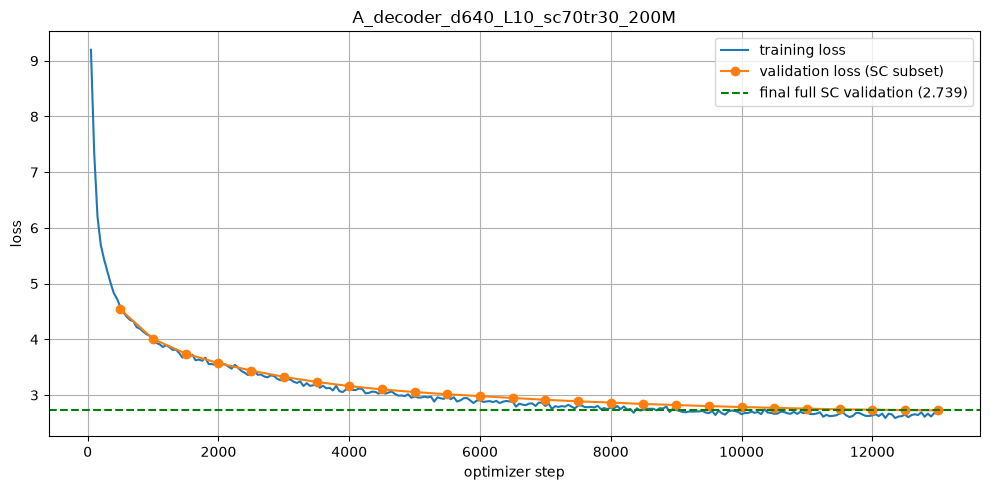

In [8]:
import matplotlib.pyplot as plt
tr = [(h["step"], h["train_loss"]) for h in history]
ev = [(h["step"], h["val_loss"]) for h in history if "val_loss" in h]
plt.figure(figsize=(10, 5))
if tr: plt.plot(*zip(*tr), label="training loss")
if ev: plt.plot(*zip(*ev), marker="o", label="validation loss (SC subset)")
plt.axhline(final_eval["val_loss"], color="green", linestyle="--", label=f"final full SC validation ({final_eval['val_loss']:.3f})")
plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.title(RUN_NAME); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(RUN_DIR / "loss_curve.png", dpi=150); plt.show()

## 8. Generation (KV cache, exactly 128 words)

One prompt at a time (no padding problems at all), with a **KV cache**: the prompt is processed once, then each new token costs one tiny forward pass.

Next-token choice, in order:

1. `<|endoftext|>` and `<pad>` are **forbidden** — a continuation must never "end".
2. **Repetition penalty** on every token already in the text (prompt + output).
3. **No-repeat n-gram** (optional): if the last n−1 tokens already appeared earlier followed by token t, t is forbidden now. This directly blocks loops like `27/87, 27/87, 27/87` that broke the baseline. The lookup table is updated incrementally (one entry per new token), so it costs almost nothing.
4. **Greedy** (`temperature = 0`) or **sampling** with temperature and top-p.

**Stopping:** every 16 tokens we decode and count whitespace words; we stop once there are **more than 128** (so the 128th word is complete), then keep exactly the first 128.
**Guarantee:** if a run still has < 128 words after 400 new tokens (a loop of text without spaces), we retry once with a stronger anti-repetition setting. The number of retries is reported.


In [9]:
MAX_NEW_TOKENS = 400
TARGET_WORDS = 128
MAX_PROMPT_TOKENS = CFG["max_seq_len"] - MAX_NEW_TOKENS           # 1136 >= longest test prompt (~982)
BANNED = [EOS_ID, PAD_ID]

@torch.no_grad()
def generate_words(model, prompt_ids, temperature=0.1, top_p=0.95, rep_penalty=1.1, no_repeat_ngram=0, seed=0):
    gen = torch.Generator(device=device).manual_seed(seed)
    seq = list(prompt_ids[-MAX_PROMPT_TOKENS:])
    n_prompt = len(seq)
    seen = torch.zeros(CFG["vocab_size"], dtype=torch.bool, device=device)
    seen[torch.tensor(seq, device=device)] = True
    ngrams = {}
    if no_repeat_ngram:
        n = no_repeat_ngram
        for j in range(len(seq) - n + 1):
            ngrams.setdefault(tuple(seq[j:j + n - 1]), set()).add(seq[j + n - 1])

    cache = [dict() for _ in model.blocks]
    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
        logits = model(torch.tensor([seq], device=device), cache=cache, start_pos=0)[0]
    words = []
    for t in range(MAX_NEW_TOKENS):
        logits[BANNED] = -float("inf")
        if rep_penalty != 1.0:
            pen = logits[seen]
            logits[seen] = torch.where(pen > 0, pen / rep_penalty, pen * rep_penalty)
        if no_repeat_ngram and len(seq) >= no_repeat_ngram - 1:
            banned = ngrams.get(tuple(seq[len(seq) - no_repeat_ngram + 1:]))
            if banned:
                logits[list(banned)] = -float("inf")
        if temperature == 0:
            nxt = int(torch.argmax(logits))
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sp, si = torch.sort(probs, descending=True)
            cut = torch.cumsum(sp, dim=-1) - sp > top_p          # drop tokens outside the top-p nucleus
            sp[cut] = 0
            nxt = int(si[torch.multinomial(sp / sp.sum(), 1, generator=gen)])
        seq.append(nxt); seen[nxt] = True
        if no_repeat_ngram and len(seq) >= no_repeat_ngram:
            ngrams.setdefault(tuple(seq[-no_repeat_ngram:-1]), set()).add(nxt)
        if (t + 1) % 16 == 0 or t == MAX_NEW_TOKENS - 1:
            words = tokenizer.decode(seq[n_prompt:]).split()
            if len(words) > TARGET_WORDS:
                break
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            logits = model(torch.tensor([[nxt]], device=device), cache=cache, start_pos=len(seq) - 1)[0]
    return words[:TARGET_WORDS]

RETRY_CFG = {"temperature": 0.7, "top_p": 0.9, "rep_penalty": 1.2, "no_repeat_ngram": 4}

def continue_prompt(model, prompt_text, dcfg, seed):
    ids = tokenizer.encode(clean_text(prompt_text)).ids
    words = generate_words(model, ids, seed=seed, **dcfg)
    retried = False
    if len(words) < TARGET_WORDS:
        words, retried = generate_words(model, ids, seed=seed + 1, **RETRY_CFG), True
    return " ".join(words), retried

def predict_all(model, prompts, dcfg, desc, limit=None):
    model.eval()
    items = list(prompts.items())[:limit]
    preds, retries = {}, 0
    for k, (pid, rec) in enumerate(tqdm(items, desc=desc)):
        text, retried = continue_prompt(model, rec["text"], dcfg, seed=CFG["seed"] + k)
        preds[str(pid)] = {"text": text}
        retries += retried
    return preds, retries

## 9. Local evaluation (cached)

Three decoding settings on the **new** local evaluation set (200 cleaned SC validation prompts), each with a fixed seed (reproducible), scored by the **official, unchanged** `evaluate_phase1.py`.
Settings compared: the baseline's winner (T=0.1 + repetition penalty 1.1), the same **+ no-repeat 6-gram**, and **greedy + no-repeat 6-gram**.


In [10]:
SWEEP = {
    "T0.1_rep1.1":         {"temperature": 0.1, "top_p": 0.95, "rep_penalty": 1.1, "no_repeat_ngram": 0},
    "T0.1_rep1.1_nrng6":   {"temperature": 0.1, "top_p": 0.95, "rep_penalty": 1.1, "no_repeat_ngram": 6},
    "greedy_rep1.1_nrng6": {"temperature": 0.0, "top_p": 1.0,  "rep_penalty": 1.1, "no_repeat_ngram": 6},
}
local_prompts = json.load(open(EVAL_DIR / "local_eval_prompts.json"))
LOCAL_LIMIT = 16 if SMOKE_TEST else None
truth_path = EVAL_DIR / "local_eval_truth.json"
if LOCAL_LIMIT:                                                  # smoke test: evaluator needs matching truth ids
    keep = list(local_prompts)[:LOCAL_LIMIT]
    truth_path = RUN_DIR / "local_truth_subset.json"
    full_truth = json.load(open(EVAL_DIR / "local_eval_truth.json"))
    json.dump({k: full_truth[k] for k in keep}, open(truth_path, "w"))

def run_official_eval(pred_path, truth_path):
    env = dict(os.environ, PYTHONUTF8="1")
    r = subprocess.run([sys.executable, str(EVAL_SCRIPT), "--truth", str(truth_path), "--prediction", str(pred_path)],
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    if r.returncode != 0:
        print(r.stderr[-2000:]); return None
    scores = {}
    for line in r.stdout.splitlines():
        key, _, val = line.partition(":")
        if key.strip() in ("BERTScore F1", "ROUGE-L F1", "BLEU-4"):
            scores[key.strip()] = float(val)
    return scores

LOCAL_RESULTS = RUN_DIR / "local_eval_results.json"
local_results = json.load(open(LOCAL_RESULTS)) if LOCAL_RESULTS.exists() else {}
for name, dcfg in SWEEP.items():
    if name in local_results:
        print(f"[cache] {name}: {local_results[name]}")
        continue
    preds, retries = predict_all(model, local_prompts, dcfg, desc=f"local {name}", limit=LOCAL_LIMIT)
    pred_path = RUN_DIR / f"local_pred_{name}.json"
    json.dump(preds, open(pred_path, "w"), indent=1)
    scores = run_official_eval(pred_path, truth_path)
    local_results[name] = {**(scores or {}), "retries": retries}
    json.dump(local_results, open(LOCAL_RESULTS, "w"), indent=1)      # saved after EACH setting
    print(f"{name}: {local_results[name]}")

local T0.1_rep1.1: 100%|██████████| 200/200 [06:43<00:00,  2.02s/it]


T0.1_rep1.1: {'BERTScore F1': 0.813746, 'ROUGE-L F1': 0.192734, 'BLEU-4': 0.039368, 'retries': 2}


local T0.1_rep1.1_nrng6: 100%|██████████| 200/200 [06:50<00:00,  2.05s/it]


T0.1_rep1.1_nrng6: {'BERTScore F1': 0.826084, 'ROUGE-L F1': 0.192109, 'BLEU-4': 0.039233, 'retries': 2}


local greedy_rep1.1_nrng6: 100%|██████████| 200/200 [06:30<00:00,  1.95s/it]


greedy_rep1.1_nrng6: {'BERTScore F1': 0.825426, 'ROUGE-L F1': 0.191719, 'BLEU-4': 0.039129, 'retries': 2}


## 10. Test predictions → checks → submission.zip (cached)

Uses the decoding setting with the best local BERTScore. Checks before zipping: same IDs as `test.json`, no empty text, **every prediction exactly 128 words**.


In [11]:
from huggingface_hub import hf_hub_download
test_data = json.load(open(hf_hub_download("Exploration-Lab/CS-781-Capstone", "Phase_1_Pretraining/Test/test.json",
                                           repo_type="dataset"), encoding="utf-8"))
PRED_PATH, ZIP_PATH = RUN_DIR / "prediction.json", RUN_DIR / "submission.zip"

if ZIP_PATH.exists():
    print("[cache] submission already exists:", ZIP_PATH)
else:
    best = max(local_results, key=lambda n: local_results[n].get("BERTScore F1", -1))
    print("Decoding:", best, SWEEP[best])
    preds, retries = predict_all(model, test_data, SWEEP[best], desc="test", limit=20 if SMOKE_TEST else None)
    wc = [len(p["text"].split()) for p in preds.values()]
    print(f"{len(preds)} predictions | words min={min(wc)} max={max(wc)} | not 128: {sum(w != 128 for w in wc)} | retries: {retries}")
    if not SMOKE_TEST:
        assert set(preds) == set(test_data), "ID mismatch with test.json"
        assert all(p["text"].strip() for p in preds.values()), "empty prediction"
        json.dump(preds, open(PRED_PATH, "w"), indent=1)
        with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
            z.write(PRED_PATH, arcname="prediction.json")
        print(zipfile.ZipFile(ZIP_PATH).namelist(), "->", ZIP_PATH)

Decoding: T0.1_rep1.1_nrng6 {'temperature': 0.1, 'top_p': 0.95, 'rep_penalty': 1.1, 'no_repeat_ngram': 6}


test: 100%|██████████| 1000/1000 [33:30<00:00,  2.01s/it]

1000 predictions | words min=128 max=128 | not 128: 0 | retries: 2
['prediction.json'] -> c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\checkpoints\phase1\A_decoder_d640_L10_sc70tr30_200M\submission.zip


## 11. Log the experiment (once per run)


In [12]:
def logged_runs():
    # run names already in the log; skips blank or broken lines instead of crashing
    runs = set()
    if EXP_LOG.exists():
        for line in open(EXP_LOG, encoding="utf-8"):
            line = line.strip()
            if not line:
                continue                      # blank line -> ignore
            try:
                runs.add(json.loads(line).get("run"))
            except json.JSONDecodeError:
                pass                          # broken line -> ignore
    return runs

already = RUN_NAME in logged_runs()
if already or SMOKE_TEST:
    print("Not logging (already logged or smoke test).")
else:
    t = json.load(open(RUN_DIR / "train_time.json")) if (RUN_DIR / "train_time.json").exists() else {}
    entry = {"run": RUN_NAME, "time": time.strftime("%Y-%m-%d %H:%M"), "arch": CFG["arch"],
             "params_M": round(n_params / 1e6, 2), "train_tokens": CFG["train_tokens"], "mix": CFG["mix"],
             "ctx": CFG["max_seq_len"], "tokens_per_step": tokens_per_step, "lr": CFG["lr"],
             "train_hours": t.get("train_hours_this_session"), **final_eval, "local_eval": local_results}
    with open(EXP_LOG, "a") as f:
        f.write(json.dumps(entry) + "\n")
    print(json.dumps(entry, indent=1))

{
 "run": "A_decoder_d640_L10_sc70tr30_200M",
 "time": "2026-09-30 06:26",
 "arch": "A_decoder",
 "params_M": 70.06,
 "train_tokens": 200000000,
 "mix": {
  "sc": 0.7,
  "tribunals": 0.3
 },
 "ctx": 1536,
 "tokens_per_step": 15360,
 "lr": 0.0003,
 "train_hours": 2.680062674548891,
 "val_loss": 2.7394888774332817,
 "perplexity": 15.479071371380758,
 "bits_per_char": 0.8115429222971487,
 "val_tokens": 2815488,
 "local_eval": {
  "T0.1_rep1.1": {
   "BERTScore F1": 0.813746,
   "ROUGE-L F1": 0.192734,
   "BLEU-4": 0.039368,
   "retries": 2
  },
  "T0.1_rep1.1_nrng6": {
   "BERTScore F1": 0.826084,
   "ROUGE-L F1": 0.192109,
   "BLEU-4": 0.039233,
   "retries": 2
  },
  "greedy_rep1.1_nrng6": {
   "BERTScore F1": 0.825426,
   "ROUGE-L F1": 0.191719,
   "BLEU-4": 0.039129,
   "retries": 2
  }
 }
}


## Viva check

1. What does RoPE do differently from learned position embeddings, and why does the attention score then depend on _relative_ position?
2. Why does RMSNorm work without subtracting the mean? Why compute it in float32?
3. Why is the SwiGLU hidden size 1728 and not 2560?
4. Where exactly do we shift inputs and targets by one token in _our_ loop?
5. What is in `ckpt_last.pt` and why do we need the optimizer state to resume?
6. How does the KV cache make generation faster? What is stored per layer?
7. How does the no-repeat n-gram rule prevent `27/87, 27/87, …` loops?
8. Why can bits-per-character compare models with different tokenizers when perplexity cannot?
